
Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64016 entries, 0 to 64015
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   img           64016 non-null  object 
 1   title         64016 non-null  object 
 2   console       64016 non-null  object 
 3   genre         64016 non-null  object 
 4   publisher     64016 non-null  object 
 5   developer     63999 non-null  object 
 6   critic_score  6678 non-null   float64
 7   total_sales   18922 non-null  float64
 8   na_sales      12637 non-null  float64
 9   jp_sales      6726 non-null   float64
 10  pal_sales     12824 non-null  float64
 11  other_sales   15128 non-null  float64
 12  release_date  56965 non-null  object 
 13  last_update   17879 non-null  object 
dtypes: float64(6), object(8)
memory usage: 6.8+ MB

First five rows:
                                             img                        title  \
0  /games/boxart/full_6510540A

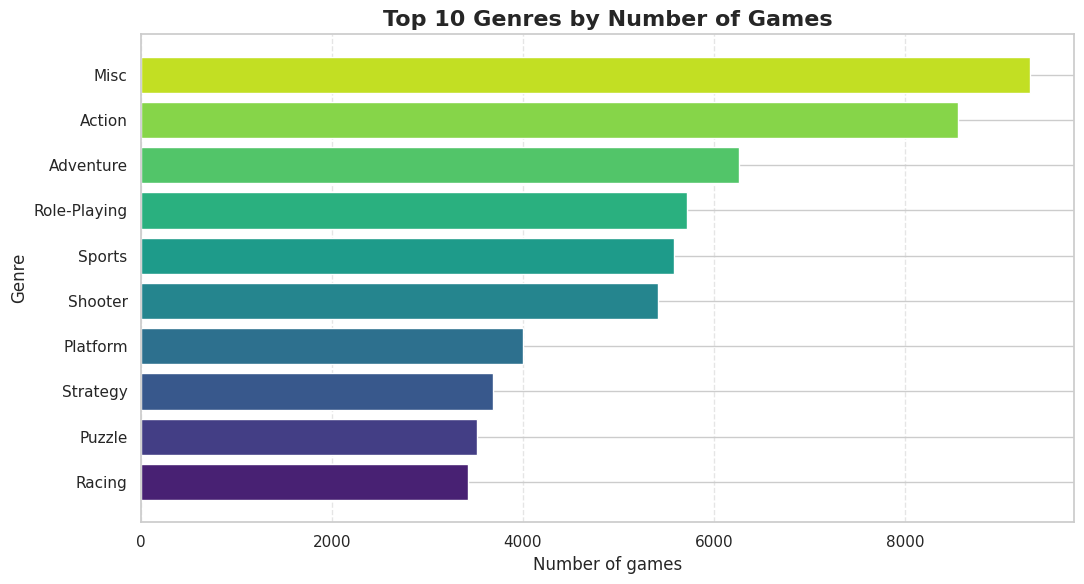

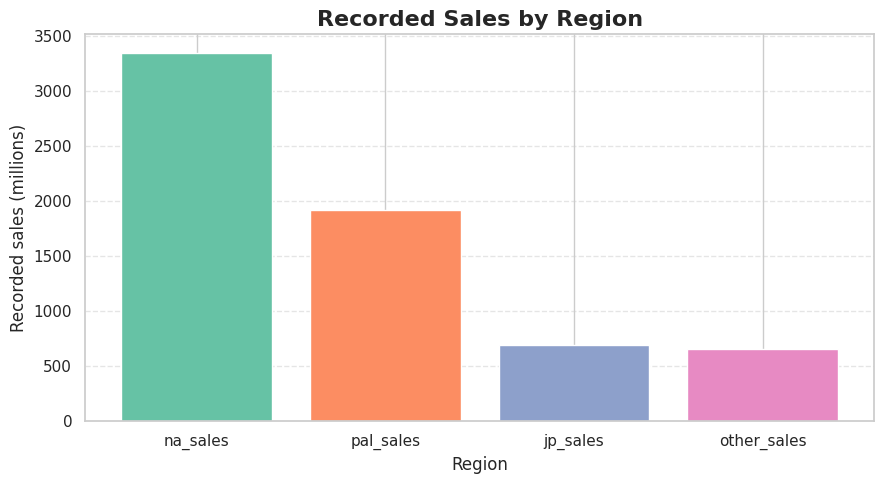

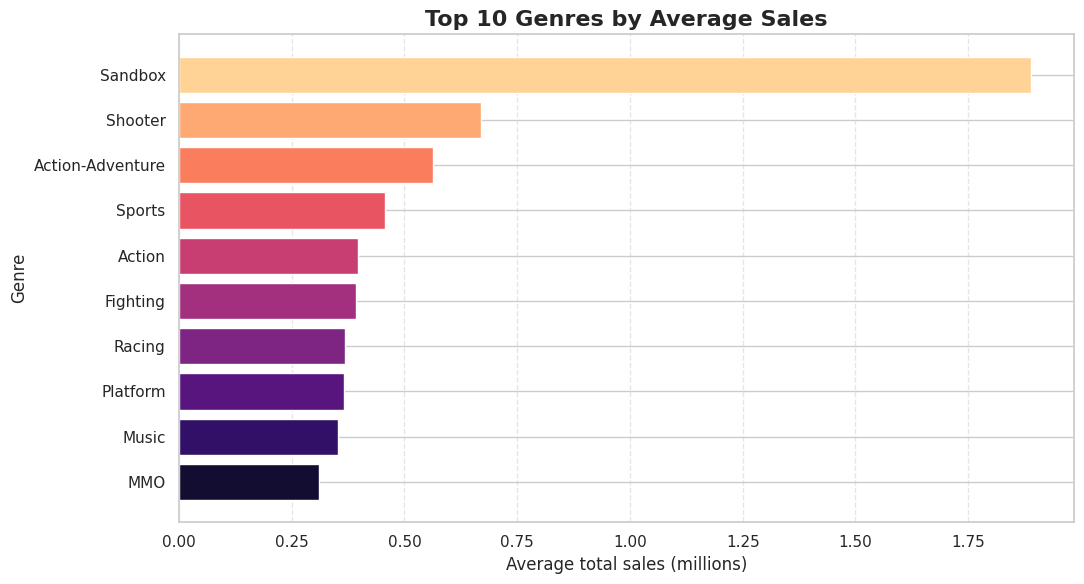

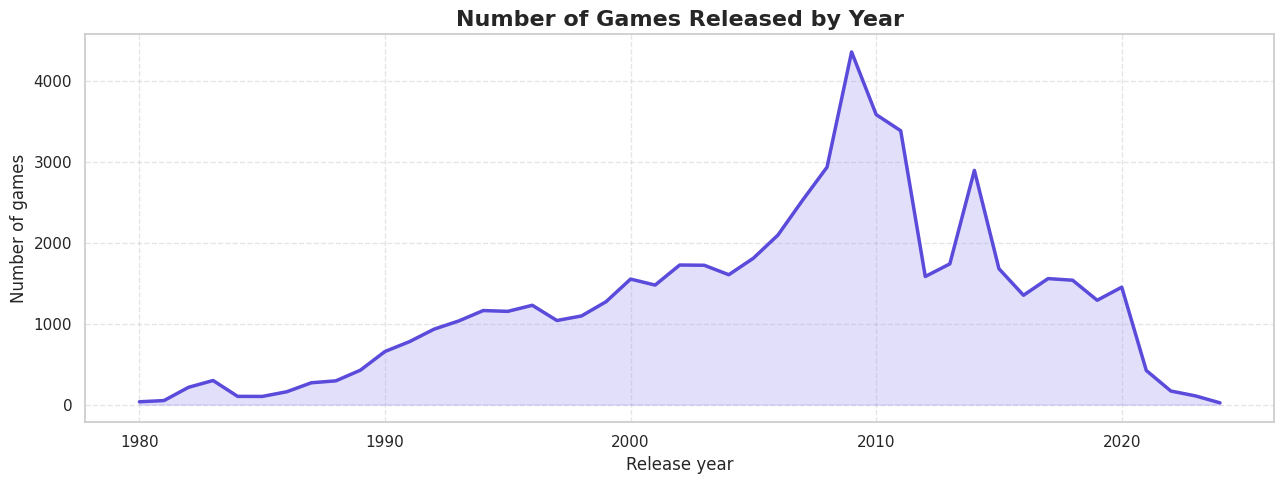

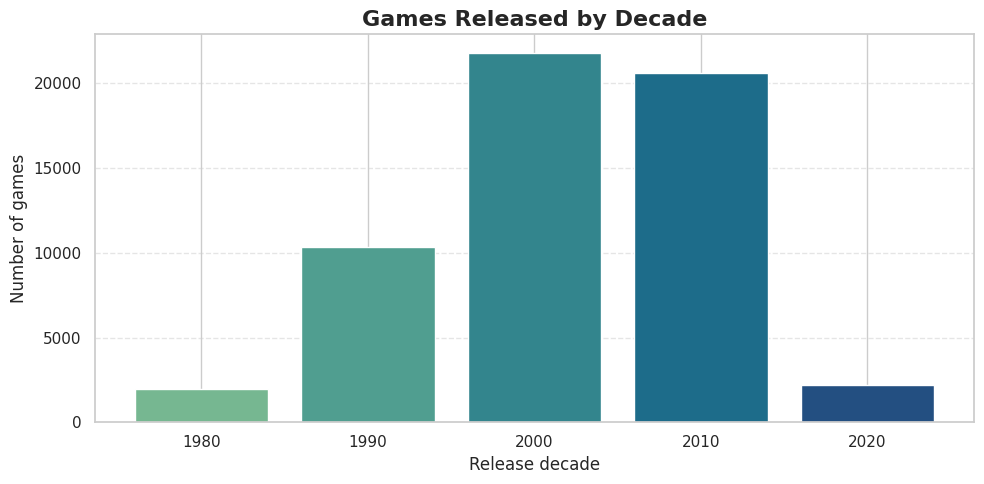

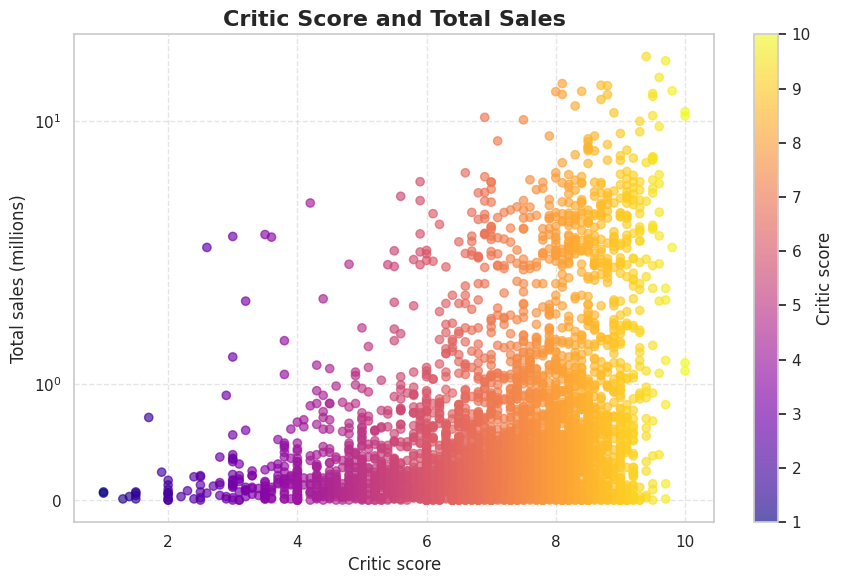

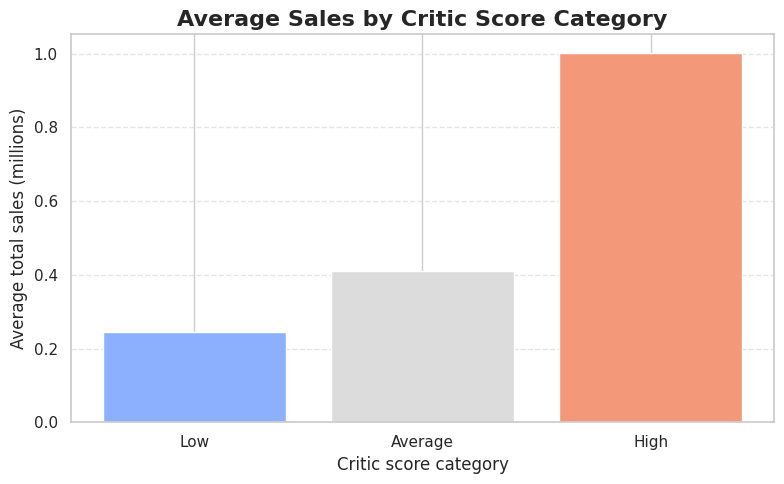

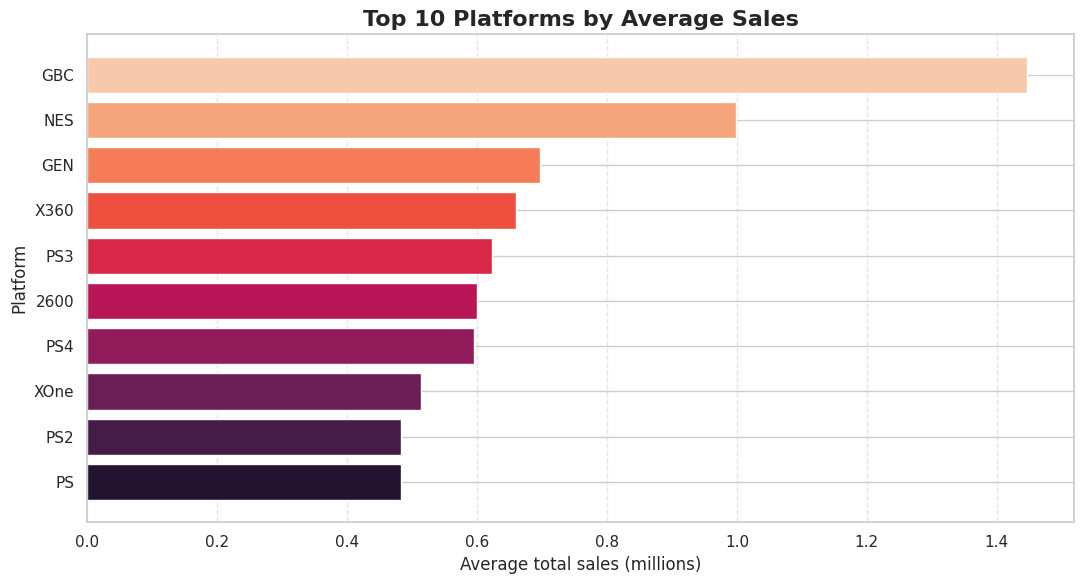

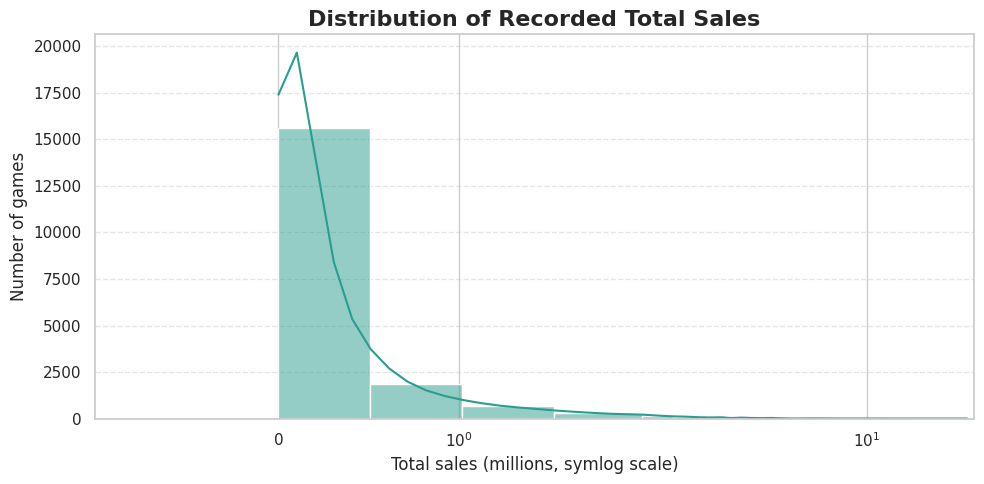

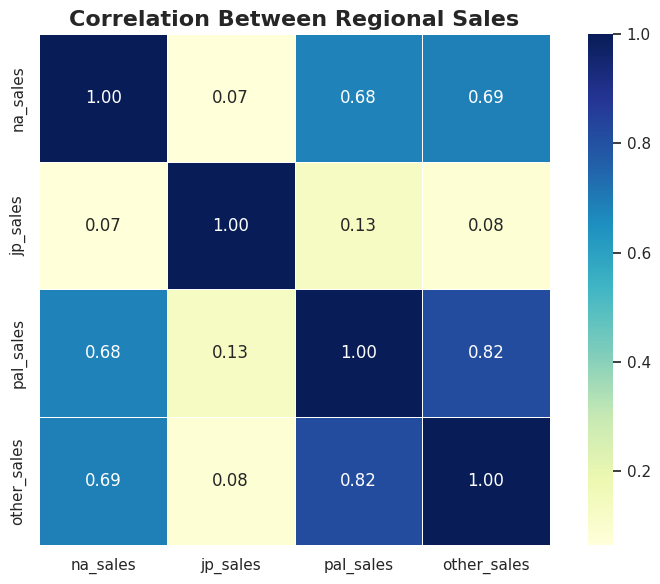


Model evaluation:
            Model   MAE  RMSE     R2
              KNN 0.313 0.762  0.206
    Random Forest 0.304 0.769  0.191
Linear Regression 0.363 0.807  0.109
    Decision Tree 0.341 0.966 -0.275

Best-fit model based on lowest RMSE: KNN
MAE: 0.313
RMSE: 0.762
R2: 0.206

Percentage of missing total sales:
70.44 %


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor


df = pd.read_csv("Video Games Sales (1980-2024) - Raw.csv")

print("\nDataset information:")
df.info()

print("\nFirst five rows:")
print(df.head())

print("\nLast five rows:")
print(df.tail())

print("\nSummary statistics:")
print(df.describe())

print("\nSummary statistics including text columns:")
print(df.describe(include="all"))

print("\nMissing values before cleaning:")
print(df.isna().sum())

print("\nExact duplicate rows:", df.duplicated().sum())


text_columns = [
    "img", "title", "console", "genre",
    "publisher", "developer"
]

for column in text_columns:
    df[column] = df[column].astype("string").str.strip()
    df[column] = df[column].replace("", pd.NA)

for column in ["publisher", "developer"]:
    df[column] = df[column].fillna("Unknown")

for column in ["release_date", "last_update"]:
    df[column] = pd.to_datetime(
        df[column],
        format="%d-%m-%Y",
        errors="coerce"
    )

out_of_range_dates = (
    df["release_date"].notna()
    & ~df["release_date"].dt.year.between(1980, 2024)
)
print("Release dates outside 1980-2024 set to missing:", int(out_of_range_dates.sum()))
df.loc[out_of_range_dates, "release_date"] = pd.NaT

numeric_columns = [
    "critic_score", "total_sales", "na_sales",
    "jp_sales", "pal_sales", "other_sales"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

    if "sales" in column:
        df.loc[df[column] < 0, column] = np.nan

df.loc[
    (df["critic_score"] < 1) | (df["critic_score"] > 10),
    "critic_score"
] = np.nan

region_columns = ["na_sales", "jp_sales", "pal_sales", "other_sales"]

can_calculate_total = (
    df["total_sales"].isna()
    & df[region_columns].notna().all(axis=1)
)

df.loc[can_calculate_total, "total_sales"] = (
    df.loc[can_calculate_total, region_columns].sum(axis=1)
)

rows_before_cleaning = len(df)

df = df.drop_duplicates()
df = df.dropna(subset=["title", "console", "genre"])

rows_removed = rows_before_cleaning - len(df)

print("\nRows removed for missing title, console, or genre:", rows_removed)
print("\nCleaned dataset shape:", df.shape)

print("\nMissing values after cleaning:")
print(df.isna().sum())

print("\nSummary statistics after cleaning:")
print(df.describe())


df["release_year"] = df["release_date"].dt.year
df["release_decade"] = (df["release_year"] // 10 * 10).astype("Int64")

df["critic_score_category"] = pd.cut(
    df["critic_score"],
    bins=[0, 4, 7, 10],
    labels=["Low", "Average", "High"]
)

df["regional_sales_sum"] = df[region_columns].sum(axis=1, min_count=1)
df["na_sales_share"] = (
    df["na_sales"] / df["regional_sales_sum"].replace(0, np.nan)
)

df.to_csv("Video_Games_Sales_Cleaned.csv", index=False)
df.to_csv("Video_Games_Sales_Featured.csv", index=False)

visualization_dir = Path("visualizations")
visualization_dir.mkdir(exist_ok=True)


print("\nMost common genres:")
print(df["genre"].value_counts().head(10))

print("\nMost common platforms:")
print(df["console"].value_counts().head(10))

print("\nTop 10 games by recorded total sales:")
print(
    df.nlargest(10, "total_sales")[
        ["title", "console", "total_sales"]
    ].to_string(index=False)
)


sns.set_theme(style="whitegrid", context="notebook")

genre_counts = df["genre"].value_counts().head(10).sort_values()

plt.figure(figsize=(11, 6))
plt.barh(
    genre_counts.index,
    genre_counts.values,
    color=sns.color_palette("viridis", len(genre_counts))
)
plt.title("Top 10 Genres by Number of Games", fontsize=16, weight="bold")
plt.xlabel("Number of games")
plt.ylabel("Genre")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(visualization_dir / "F1_genre_counts.png", dpi=300, bbox_inches="tight")
plt.show()


regional_sales = df[region_columns].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
plt.bar(
    regional_sales.index,
    regional_sales.values,
    color=sns.color_palette("Set2", len(regional_sales))
)
plt.title("Recorded Sales by Region", fontsize=16, weight="bold")
plt.xlabel("Region")
plt.ylabel("Recorded sales (millions)")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(visualization_dir / "F2_regional_sales.png", dpi=300, bbox_inches="tight")
plt.show()


average_sales_by_genre = (
    df.dropna(subset=["total_sales"])
      .groupby("genre")["total_sales"]
      .mean()
      .sort_values(ascending=False)
      .head(10)
      .sort_values()
)

plt.figure(figsize=(11, 6))
plt.barh(
    average_sales_by_genre.index,
    average_sales_by_genre.values,
    color=sns.color_palette("magma", len(average_sales_by_genre))
)
plt.title("Top 10 Genres by Average Sales", fontsize=16, weight="bold")
plt.xlabel("Average total sales (millions)")
plt.ylabel("Genre")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(visualization_dir / "F3_average_sales_by_genre.png", dpi=300, bbox_inches="tight")
plt.show()


games_by_year = (
    df.dropna(subset=["release_year"])
      .groupby("release_year")
      .size()
)

plt.figure(figsize=(13, 5))
plt.plot(
    games_by_year.index,
    games_by_year.values,
    color="#5B4BDB",
    linewidth=2.5
)
plt.fill_between(
    games_by_year.index,
    games_by_year.values,
    color="#8D83F3",
    alpha=0.25
)
plt.title("Number of Games Released by Year", fontsize=16, weight="bold")
plt.xlabel("Release year")
plt.ylabel("Number of games")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(visualization_dir / "F4_games_by_year.png", dpi=300, bbox_inches="tight")
plt.show()


games_by_decade = (
    df.dropna(subset=["release_decade"])
      .groupby("release_decade")
      .size()
)

plt.figure(figsize=(10, 5))
plt.bar(
    games_by_decade.index.astype(str),
    games_by_decade.values,
    color=sns.color_palette("crest", len(games_by_decade))
)
plt.title("Games Released by Decade", fontsize=16, weight="bold")
plt.xlabel("Release decade")
plt.ylabel("Number of games")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(visualization_dir / "F5_games_by_decade.png", dpi=300, bbox_inches="tight")
plt.show()


score_sales = df.dropna(subset=["critic_score", "total_sales"])

plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    score_sales["critic_score"],
    score_sales["total_sales"],
    c=score_sales["critic_score"],
    cmap="plasma",
    alpha=0.65
)
plt.colorbar(scatter, label="Critic score")
plt.title("Critic Score and Total Sales", fontsize=16, weight="bold")
plt.xlabel("Critic score")
plt.ylabel("Total sales (millions)")
plt.yscale("symlog")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(visualization_dir / "F6_critic_score_vs_sales.png", dpi=300, bbox_inches="tight")
plt.show()


average_sales_by_score = (
    df.dropna(subset=["critic_score_category", "total_sales"])
      .groupby("critic_score_category", observed=False)["total_sales"]
      .mean()
      .reindex(["Low", "Average", "High"])
)

plt.figure(figsize=(8, 5))
plt.bar(
    average_sales_by_score.index,
    average_sales_by_score.values,
    color=sns.color_palette("coolwarm", len(average_sales_by_score))
)
plt.title("Average Sales by Critic Score Category", fontsize=16, weight="bold")
plt.xlabel("Critic score category")
plt.ylabel("Average total sales (millions)")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(visualization_dir / "F7_sales_by_score_category.png", dpi=300, bbox_inches="tight")
plt.show()


platform_sales = (
    df.dropna(subset=["total_sales"])
      .groupby("console")["total_sales"]
      .mean()
      .sort_values(ascending=False)
      .head(10)
      .sort_values()
)

plt.figure(figsize=(11, 6))
plt.barh(
    platform_sales.index,
    platform_sales.values,
    color=sns.color_palette("rocket", len(platform_sales))
)
plt.title("Top 10 Platforms by Average Sales", fontsize=16, weight="bold")
plt.xlabel("Average total sales (millions)")
plt.ylabel("Platform")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(visualization_dir / "F8_average_sales_by_platform.png", dpi=300, bbox_inches="tight")
plt.show()


plt.figure(figsize=(10, 5))
sns.histplot(
    df["total_sales"].dropna(),
    bins=40,
    kde=True,
    color="#2A9D8F",
    edgecolor="white"
)
plt.xscale("symlog")
plt.title("Distribution of Recorded Total Sales", fontsize=16, weight="bold")
plt.xlabel("Total sales (millions, symlog scale)")
plt.ylabel("Number of games")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(visualization_dir / "F9_sales_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


plt.figure(figsize=(8, 6))
sns.heatmap(
    df[region_columns].corr(),
    annot=True,
    cmap="YlGnBu",
    fmt=".2f",
    linewidths=0.5,
    square=True
)
plt.title("Correlation Between Regional Sales", fontsize=16, weight="bold")
plt.tight_layout()
plt.savefig(visualization_dir / "F10_regional_sales_correlation.png", dpi=300, bbox_inches="tight")
plt.show()


model_features = [
    "critic_score",
    "release_year",
    "console",
    "genre"
]

model_data = df[model_features + ["total_sales"]].dropna(
    subset=["total_sales"]
)

X = model_data[model_features]
y = model_data["total_sales"]

numeric_features = ["critic_score", "release_year"]
categorical_features = ["console", "genre"]

numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_preprocessor, numeric_features),
    ("categorical", categorical_preprocessor, categorical_features)
])

models = {
    "KNN": KNeighborsRegressor(n_neighbors=5),
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=12,
        random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    )
}

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

results = []

for model_name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results).sort_values("RMSE")
results_df.to_csv("Model_Evaluation_Results.csv", index=False)

print("\nModel evaluation:")
print(results_df.round(3).to_string(index=False))

best_result = results_df.iloc[0]

print("\nBest-fit model based on lowest RMSE:", best_result["Model"])
print("MAE:", round(best_result["MAE"], 3))
print("RMSE:", round(best_result["RMSE"], 3))
print("R2:", round(best_result["R2"], 3))

print("\nPercentage of missing total sales:")
print(round(df["total_sales"].isna().mean() * 100, 2), "%")
